**PROYECTO:**
**Modelado espacial para estimar la susceptibilidad a inundaciones usando algoritmos de aprendizaje automatico con datos geomorfologicos**

Autor: Sebastian Velosa Bohorquez, Curso: Percepción Remota Avanzada,

**NOTEBOOK 07/07**

#Entrenamiento Modelos RF




**Objetivo:**

Importar datos raster de tres modelos digitales de elevación DEM/DTM para el proyecto


**Contenido:**

1. Instalación de Librerias
2. Verificacipon de los tres archivos `.CSV`
3. Graficar los puntos seleccionados
4. Entrenamiento de los tres modelos
5. Evaluacíon de los modelos con Test
6. Comparar desempeño y exactitud
7. Matrices de confusión y curvas ROC
8. Importancia de las variables y exportación

**Resultados:**

Archivos de resultados:

* comparacion_final_test.csv
* importancia_variables.csv
* resultados_validacion.csv





##1. Instalación de Librerias y Carga de archivos

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, roc_curve
)

# Rutas de los CSV
CARPETA = '/content/drive//MyDrive/Sinu_Flood_Susceptibility/04_samples/'

ARCHIVOS = {
    'FABDEM': f'{CARPETA}/muestras_fabdem_5000.csv',
    'Copernicus': f'{CARPETA}/muestras_copernicus_5000.csv',
    'ANADEM': f'{CARPETA}/muestras_anadem_5000.csv'
}

SALIDA = f'{CARPETA}/resultados_rf'
os.makedirs(SALIDA, exist_ok=True)

# Nombres de las nueve variables
VARIABLES = [
    'Elevation', 'Slope', 'HAND',
    'FlowAccumulation', 'DistRiver',
    'TWI', 'Curvature', 'TPI', 'TRI'
]

OBJETIVO = 'Flood'
SEMILLA = 42

datos = {
    nombre: pd.read_csv(ruta)
    for nombre, ruta in ARCHIVOS.items()
}

print('CSV cargados:')
for nombre, df in datos.items():
    print(nombre, df.shape)


Mounted at /content/drive
CSV cargados:
FABDEM (5000, 16)
Copernicus (5000, 16)
ANADEM (5000, 16)


## 2. Verificacipon de los tres archivos `.CSV` sean comparables

In [ ]:

columnas_control = [
    'sample_id', 'row', 'col', 'Flood', 'split'
]

base = (
    datos['FABDEM'][columnas_control]
    .sort_values('sample_id')
    .reset_index(drop=True)
)

for nombre, df in datos.items():

    requeridas = columnas_control + VARIABLES
    faltantes = [c for c in requeridas if c not in df.columns]

    if faltantes:
        raise ValueError(f'{nombre}: faltan columnas {faltantes}')

    if df[VARIABLES].isna().any().any():
        raise ValueError(f'{nombre}: existen valores nulos.')

    if not set(df['Flood'].unique()).issubset({0, 1}):
        raise ValueError(f'{nombre}: Flood debe contener 0 y 1.')

    actual = (
        df[columnas_control]
        .sort_values('sample_id')
        .reset_index(drop=True)
    )

    if not actual.equals(base):
        raise ValueError(
            f'{nombre}: las ubicaciones, etiquetas o particiones no coinciden.'
        )

    print(f'\n{nombre}')
    print('Número de muestras:', len(df))
    print(pd.crosstab(df['split'], df['Flood']))

print('\nVerificación superada.')



FABDEM
Número de muestras: 5000
Flood          0     1
split                 
test         500   500
train       1500  1500
validation   500   500

Copernicus
Número de muestras: 5000
Flood          0     1
split                 
test         500   500
train       1500  1500
validation   500   500

ANADEM
Número de muestras: 5000
Flood          0     1
split                 
test         500   500
train       1500  1500
validation   500   500

Verificación superada.


## 3. Graficar los puntos seleccionados

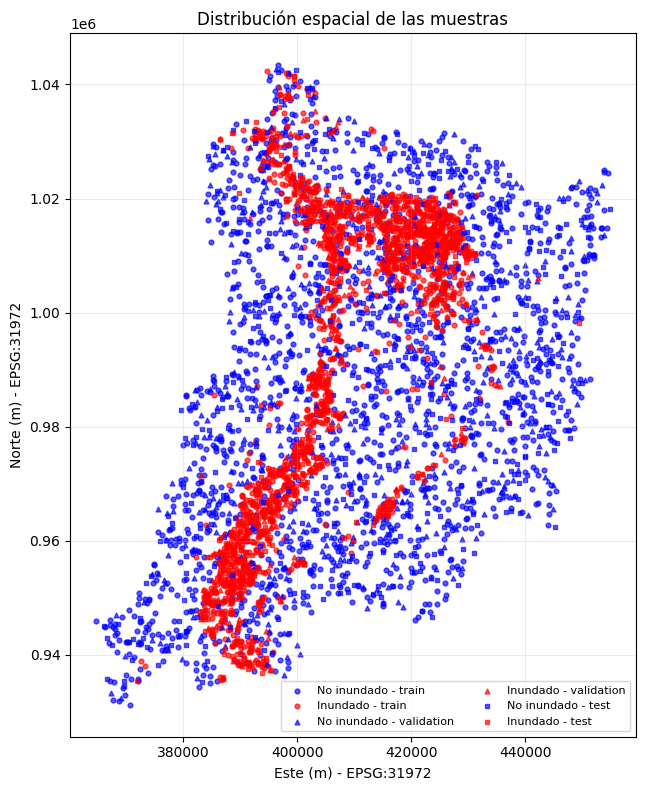

Distribución de muestras:


Flood,0,1,All
split,,,
test,500,500,1000
train,1500,1500,3000
validation,500,500,1000
All,2500,2500,5000


In [ ]:

df = datos['FABDEM']

colores = {0: 'blue', 1: 'red'}
marcadores = {
    'train': 'o',
    'validation': '^',
    'test': 's'
}

fig, ax = plt.subplots(figsize=(10, 8))

for particion, marcador in marcadores.items():
    for clase, color in colores.items():

        puntos = df[
            (df['split'] == particion) &
            (df['Flood'] == clase)
        ]

        ax.scatter(
            puntos['x'], puntos['y_coord'],
            c=color, marker=marcador,
            s=12, alpha=0.65,
            label=f'{"Inundado" if clase == 1 else "No inundado"} - {particion}'
        )

ax.set_title('Distribución espacial de las muestras')
ax.set_xlabel('Este (m) - EPSG:31972')
ax.set_ylabel('Norte (m) - EPSG:31972')
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

print('Distribución de muestras:')
display(pd.crosstab(df['split'], df['Flood'], margins=True))


## 4. Entrenamiento de los tres modelos

In [ ]:

# Hiperparámetros ajustables
CONFIGURACIONES = [
    {'n_estimators': 300, 'max_depth': None,
     'min_samples_leaf': 1, 'max_features': 'sqrt'},

    {'n_estimators': 300, 'max_depth': 20,
     'min_samples_leaf': 1, 'max_features': 'sqrt'},

    {'n_estimators': 300, 'max_depth': 30,
     'min_samples_leaf': 2, 'max_features': 'sqrt'},

    {'n_estimators': 500, 'max_depth': None,
     'min_samples_leaf': 2, 'max_features': 'sqrt'},

    {'n_estimators': 500, 'max_depth': 20,
     'min_samples_leaf': 5, 'max_features': 'sqrt'}
]

def calcular_metricas(y_real, y_pred, prob):
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_real, y_pred),
        'Precision': precision_score(y_real, y_pred, zero_division=0),
        'Recall': recall_score(y_real, y_pred, zero_division=0),
        'F1': f1_score(y_real, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_real, prob)
    }

mejores_parametros = {}
resultados_validacion = []

for nombre, df in datos.items():

    train = df[df['split'] == 'train']
    val = df[df['split'] == 'validation']

    X_train = train[VARIABLES]
    y_train = train[OBJETIVO].astype(int)

    X_val = val[VARIABLES]
    y_val = val[OBJETIVO].astype(int)

    pruebas = []

    for parametros in CONFIGURACIONES:

        modelo = RandomForestClassifier(
            **parametros,
            random_state=SEMILLA,
            n_jobs=-1,
            class_weight=None
        )

        modelo.fit(X_train, y_train)

        pred = modelo.predict(X_val)
        prob = modelo.predict_proba(X_val)[:, 1]

        pruebas.append({
            **parametros,
            **calcular_metricas(y_val, pred, prob)
        })
## Se elabora una tabla ordenada con el F1 más alto en la primera fila

    tabla = pd.DataFrame(pruebas).sort_values(
        'F1', ascending=False
    ).reset_index(drop=True)

## se guarda la primera configuracion de hiperparametros del modelo

    mejores_parametros[nombre] = {
        clave: tabla.loc[0, clave]
        for clave in [
            'n_estimators', 'max_depth',
            'min_samples_leaf', 'max_features'
        ]
    }

    tabla['DEM'] = nombre
    resultados_validacion.append(tabla)

    print(f'\nResultados de validación: {nombre}')
    display(tabla)

    print('Configuración seleccionada:')
    print(mejores_parametros[nombre])

# Exportar las pruebas de validación
pd.concat(resultados_validacion).to_csv(
    f'{SALIDA}/resultados_validacion.csv',
    index=False
)



Resultados de validación: FABDEM


,n_estimators,max_depth,min_samples_leaf,max_features,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,DEM
0,300,20.0,1,sqrt,0.865,0.865,0.834862,0.910,0.870813,0.935530,FABDEM
1,500,NaN,2,sqrt,0.865,0.865,0.838590,0.904,0.870067,0.935220,FABDEM
2,300,NaN,1,sqrt,0.863,0.863,0.835490,0.904,0.868396,0.934076,FABDEM
3,500,20.0,5,sqrt,0.861,0.861,0.834879,0.900,0.866218,0.935512,FABDEM
4,300,30.0,2,sqrt,0.860,0.860,0.832103,0.902,0.865643,0.934696,FABDEM


Configuración seleccionada:
{'n_estimators': np.int64(300), 'max_depth': np.float64(20.0), 'min_samples_leaf': np.int64(1), 'max_features': 'sqrt'}

Resultados de validación: Copernicus


,n_estimators,max_depth,min_samples_leaf,max_features,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,DEM
0,300,30.0,2,sqrt,0.863,0.863,0.825853,0.920,0.870388,0.933856,Copernicus
1,300,NaN,1,sqrt,0.862,0.862,0.820922,0.926,0.870301,0.933626,Copernicus
2,500,20.0,5,sqrt,0.862,0.862,0.822064,0.924,0.870056,0.934168,Copernicus
3,500,NaN,2,sqrt,0.862,0.862,0.824373,0.920,0.869565,0.934488,Copernicus
4,300,20.0,1,sqrt,0.859,0.859,0.817699,0.924,0.867606,0.933870,Copernicus


Configuración seleccionada:
{'n_estimators': np.int64(300), 'max_depth': np.float64(30.0), 'min_samples_leaf': np.int64(2), 'max_features': 'sqrt'}

Resultados de validación: ANADEM


,n_estimators,max_depth,min_samples_leaf,max_features,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,DEM
0,500,20.0,5,sqrt,0.869,0.869,0.833635,0.922,0.875594,0.931344,ANADEM
1,300,NaN,1,sqrt,0.869,0.869,0.834846,0.920,0.875357,0.931390,ANADEM
2,300,30.0,2,sqrt,0.867,0.867,0.831826,0.920,0.873694,0.931168,ANADEM
3,300,20.0,1,sqrt,0.867,0.867,0.833031,0.918,0.873454,0.931826,ANADEM
4,500,NaN,2,sqrt,0.865,0.865,0.830018,0.918,0.871795,0.931692,ANADEM


Configuración seleccionada:
{'n_estimators': np.int64(500), 'max_depth': np.float64(20.0), 'min_samples_leaf': np.int64(5), 'max_features': 'sqrt'}


## 5. Evaluar los modelos en test



In [ ]:
modelos_finales = {}
predicciones = {}
resultados_test = []

#reentrenamiento con los datos de validación

for nombre, df in datos.items():

    trainval = df[df['split'].isin(['train', 'validation'])]
    test = df[df['split'] == 'test']

    # Corregir los hiperparámetros para asegurar tipos compatibles con scikit-learn
    params = mejores_parametros[nombre].copy()
    if pd.isna(params['max_depth']) or params['max_depth'] is None:
        params['max_depth'] = None
    else:
        params['max_depth'] = int(params['max_depth'])

    params['n_estimators'] = int(params['n_estimators'])
    params['min_samples_leaf'] = int(params['min_samples_leaf'])

## El modelo se construye nuevamente utilizando los mejores hiperparámetros seleccionados
    modelo = RandomForestClassifier(
        **params,
        random_state=SEMILLA,
        n_jobs=-1,
        class_weight=None
    )

    modelo.fit(
        trainval[VARIABLES],
        trainval[OBJETIVO].astype(int)
    )

##se calculan las métricas:
    y_real = test[OBJETIVO].astype(int).to_numpy()
    y_pred = modelo.predict(test[VARIABLES])
    prob = modelo.predict_proba(test[VARIABLES])[:, 1]

    metricas = calcular_metricas(y_real, y_pred, prob)
    resultados_test.append({'DEM': nombre, **metricas})

    modelos_finales[nombre] = modelo
    predicciones[nombre] = {
        'real': y_real,
        'pred': y_pred,
        'prob': prob
    }

    print(f'\nReporte de clasificación: {nombre}')
    print(classification_report(
        y_real, y_pred,
        labels=[0, 1],
        target_names=['No inundado', 'Inundado'],
        zero_division=0
    ))

comparacion = pd.DataFrame(resultados_test).set_index('DEM')

display(comparacion.round(4))

comparacion.to_csv(
    f'{SALIDA}/comparacion_final_test.csv'
)


Reporte de clasificación: FABDEM
              precision    recall  f1-score   support

 No inundado       0.90      0.80      0.85       500
    Inundado       0.82      0.91      0.86       500

    accuracy                           0.86      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.86      0.86      0.86      1000


Reporte de clasificación: Copernicus
              precision    recall  f1-score   support

 No inundado       0.92      0.81      0.86       500
    Inundado       0.83      0.93      0.87       500

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000


Reporte de clasificación: ANADEM
              precision    recall  f1-score   support

 No inundado       0.89      0.79      0.84       500
    Inundado       0.81      0.91      0.86       500

    accuracy                           0.85      1000
   macro avg       0.8

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
DEM,,,,,,
FABDEM,0.856,0.856,0.8213,0.910,0.8634,0.9304
Copernicus,0.866,0.866,0.8268,0.926,0.8736,0.9255
ANADEM,0.849,0.849,0.8133,0.906,0.8571,0.9226


## 6. Comparar desempeño y exactitud

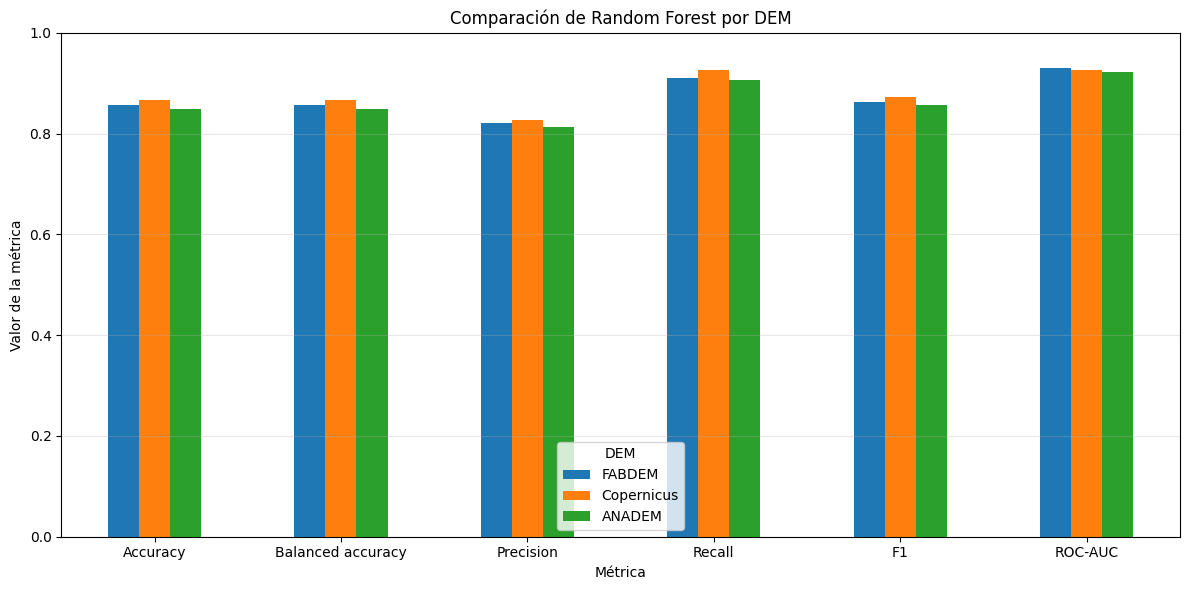

In [ ]:

metricas = [
    'Accuracy', 'Balanced accuracy',
    'Precision', 'Recall', 'F1', 'ROC-AUC'
]

ax = comparacion[metricas].T.plot(
    kind='bar', figsize=(12, 6), ylim=(0, 1)
)

ax.set_title('Comparación de Random Forest por DEM')
ax.set_ylabel('Valor de la métrica')
ax.set_xlabel('Métrica')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Matrices de confusión y curvas ROC

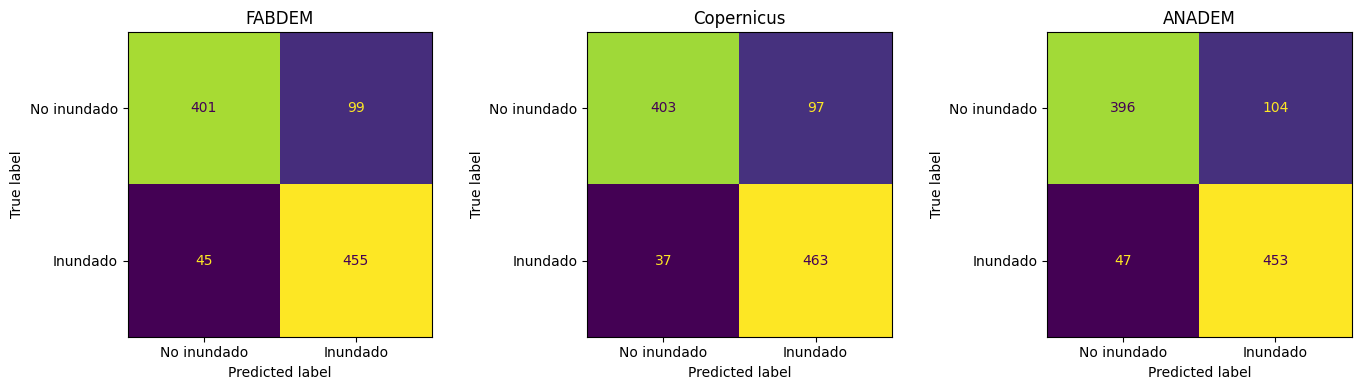

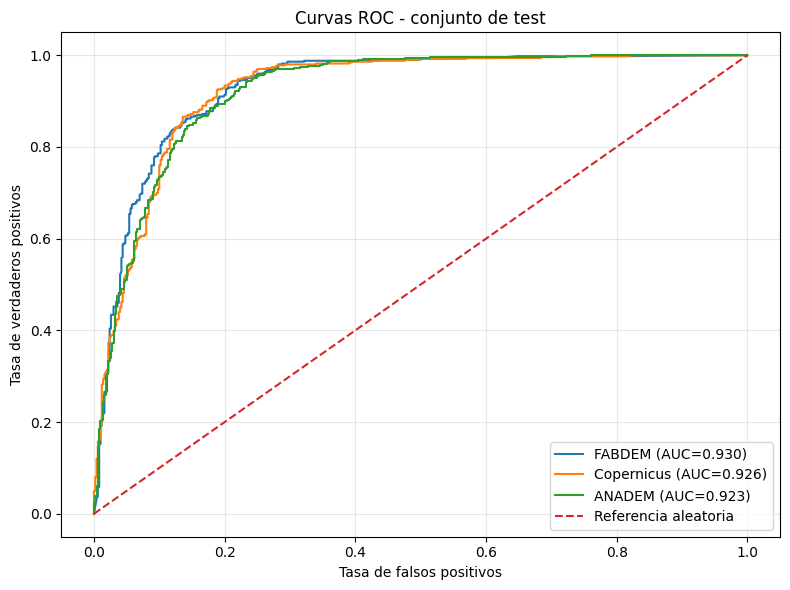

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (nombre, p) in zip(axes, predicciones.items()):

    matriz = confusion_matrix(
        p['real'], p['pred'], labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        matriz,
        display_labels=['No inundado', 'Inundado']
    ).plot(ax=ax, colorbar=False)

    ax.set_title(nombre)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

for nombre, p in predicciones.items():

    fpr, tpr, _ = roc_curve(p['real'], p['prob'])
    auc = roc_auc_score(p['real'], p['prob'])

    ax.plot(fpr, tpr, label=f'{nombre} (AUC={auc:.3f})')

ax.plot([0, 1], [0, 1], '--', label='Referencia aleatoria')
ax.set_title('Curvas ROC - conjunto de test')
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 8. Importancia de las variables y exportación

,FABDEM,Copernicus,ANADEM
Elevation,0.1957,0.2062,0.2343
Slope,0.0971,0.1003,0.0982
HAND,0.2622,0.2809,0.2813
FlowAccumulation,0.0294,0.0207,0.0176
DistRiver,0.1179,0.1178,0.1215
TWI,0.0713,0.0630,0.0533
Curvature,0.0466,0.0418,0.0308
TPI,0.0537,0.0475,0.0385
TRI,0.1260,0.1219,0.1246


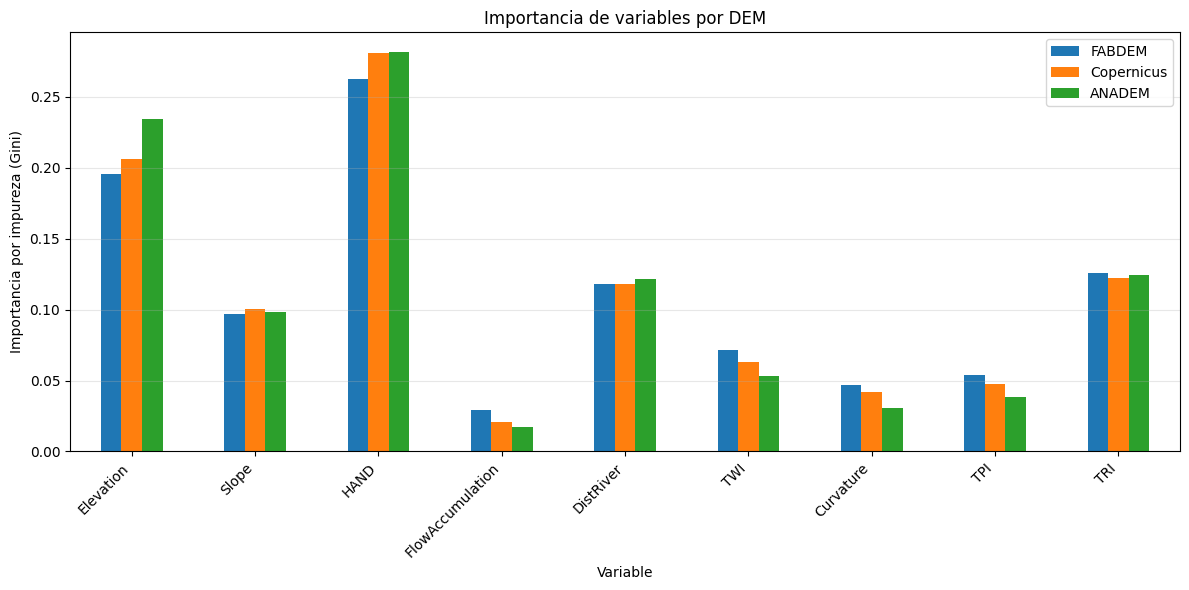

Archivos de resultados:
comparacion_final_test.csv
importancia_variables.csv
resultados_validacion.csv


In [ ]:

importancias = pd.DataFrame({
    nombre: modelo.feature_importances_
    for nombre, modelo in modelos_finales.items()
}, index=VARIABLES)

display(importancias.round(4))

importancias.to_csv(
    f'{SALIDA}/importancia_variables.csv'
)

ax = importancias.plot(kind='bar', figsize=(12, 6))
ax.set_title('Importancia de variables por DEM')
ax.set_ylabel('Importancia por impureza (Gini)')
ax.set_xlabel('Variable')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Archivos de resultados:')
for archivo in sorted(os.listdir(SALIDA)):
    print(archivo)
